# Employee Attrition Analytics Platform - Advanced Analytics, Deployment and Dashboard Data
**Person 1**  |  Version A - threshold chosen by best F1 (same method as the earlier model notebook).

This notebook extends the earlier EDA, data-preparation and classical-model notebooks. It adds: Neural Network (L2-regularised MLP; early stopping is avoided because it stops too soon on this small, imbalanced data) vs classical ML, Bayesian classification (Gaussian Naive Bayes), Discriminant Analysis (LDA/QDA), model selection, risk categories, a saved deployable model, IBM Watson Machine Learning deployment code, REST scoring, and the data used by the HR dashboard.

**Files that must sit next to this notebook:** `hr_features.py` (shared feature engineering).

## 1. Setup

In [1]:
# !pip -q install xgboost   # uncomment in Colab
import warnings, json, os, joblib
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier
from hr_features import prepare

SEED = 7
os.makedirs('outputs', exist_ok=True)
sns.set_theme(style='darkgrid', palette='deep')

## 2. Load data and prepare features

In [2]:
URL = 'https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv'
try:
    df = pd.read_csv(URL, encoding='utf-8-sig')
except Exception as e:
    print('Download failed, using local file:', e)
    df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv', encoding='utf-8-sig')
print(df.shape, '| missing:', int(df.isna().sum().sum()), '| attrition rate: %.3f' % (df['Attrition']=='Yes').mean())

data = prepare(df)                       # drops ID/constant columns, adds 5 engineered features
y = (data['Attrition'] == 'Yes').astype(int)
X = data.drop(columns=['Attrition'])
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
spw = (y_train==0).sum()/(y_train==1).sum()
print('Train', X_train.shape, 'Test', X_test.shape)

(1470, 35) | missing: 0 | attrition rate: 0.161
Train (1102, 35) Test (368, 35)


## 3. Models: classical ML vs Neural Network vs Bayesian vs Discriminant Analysis
Classical models use scaled numeric + one-hot categorical features. Gaussian Naive Bayes, LDA and QDA assume continuous Gaussian-like inputs, so they use the **numeric features only** (this is the 'where appropriate' condition for Discriminant Analysis).

In [3]:
def pre_full(scale=True):
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', num_cols),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])
def pre_num():
    return ColumnTransformer([('num', StandardScaler(), num_cols)], remainder='drop')

models = {
 'Logistic Regression': Pipeline([('pre', pre_full(True)),  ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=SEED))]),
 'Random Forest':       Pipeline([('pre', pre_full(False)), ('clf', RandomForestClassifier(n_estimators=250, class_weight='balanced_subsample', min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
 'XGBoost':             Pipeline([('pre', pre_full(False)), ('clf', XGBClassifier(n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='logloss', random_state=SEED, n_jobs=-1))]),
 'Neural Network (MLP)':Pipeline([('pre', pre_full(True)),  ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), alpha=2.0, max_iter=1000, random_state=SEED))]),
 'Gaussian Naive Bayes':Pipeline([('pre', pre_num()),       ('clf', GaussianNB())]),
 'LDA':                 Pipeline([('pre', pre_num()),       ('clf', LinearDiscriminantAnalysis())]),
 'QDA':                 Pipeline([('pre', pre_num()),       ('clf', QuadraticDiscriminantAnalysis(reg_param=0.5))]),
}
def evaluate(model, Xt, yt, thr=0.5):
    proba = model.predict_proba(Xt)[:, 1]; pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(yt, pred), 'Precision': precision_score(yt, pred, zero_division=0),
            'Recall': recall_score(yt, pred), 'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, proba)}

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = {}
for n, m in models.items():
    cv_auc = cross_val_score(m, X_train, y_train, cv=skf, scoring='roc_auc', n_jobs=-1)
    m.fit(X_train, y_train)
    rows[n] = {**evaluate(m, X_test, y_test), 'CV AUC (train)': cv_auc.mean()}
comparison = pd.DataFrame(rows).T.round(3).sort_values('CV AUC (train)', ascending=False)
comparison.to_csv('outputs/model_comparison.csv'); comparison

,Accuracy,Precision,Recall,F1,ROC-AUC,CV AUC (train)
Logistic Regression,0.769,0.390,0.780,0.520,0.853,0.808
Random Forest,0.861,0.654,0.288,0.400,0.837,0.783
XGBoost,0.848,0.523,0.576,0.548,0.849,0.780
Neural Network (MLP),0.870,0.628,0.458,0.529,0.833,0.779
LDA,0.861,0.786,0.186,0.301,0.785,0.728
Gaussian Naive Bayes,0.785,0.386,0.576,0.463,0.750,0.715
QDA,0.840,0.500,0.305,0.379,0.791,0.698


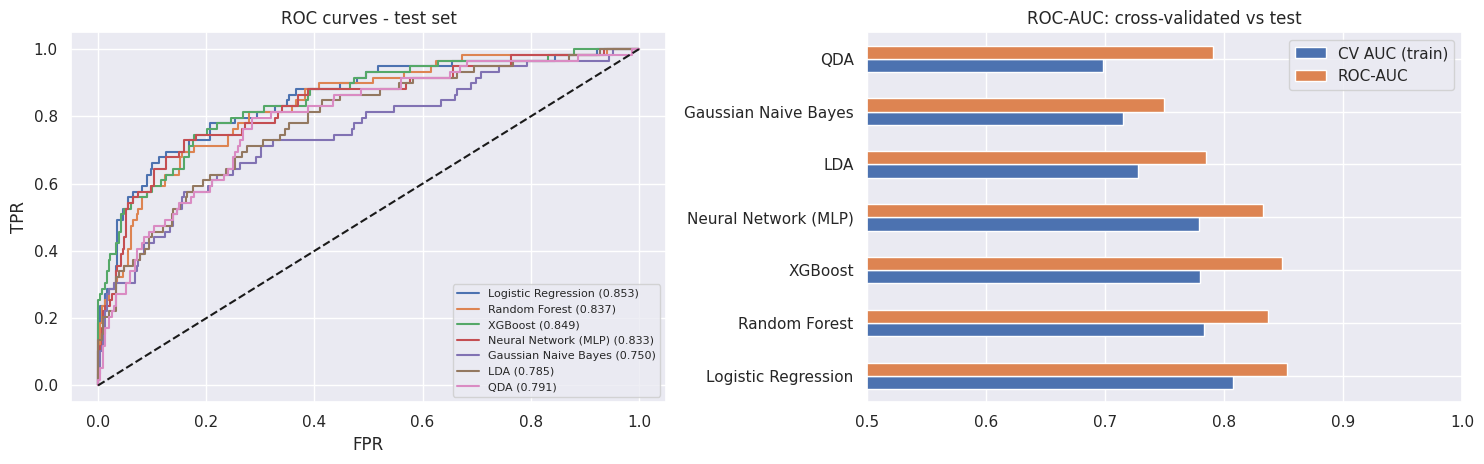

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for n, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:,1]); ax[0].plot(fpr, tpr, label=f"{n} ({rows[n]['ROC-AUC']:.3f})")
ax[0].plot([0,1],[0,1],'k--'); ax[0].legend(fontsize=8); ax[0].set_title('ROC curves - test set'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR')
comparison[['CV AUC (train)','ROC-AUC']].plot(kind='barh', ax=ax[1]); ax[1].set_title('ROC-AUC: cross-validated vs test'); ax[1].set_xlim(0.5, 1)
plt.tight_layout(); plt.savefig('outputs/model_comparison.png', dpi=130); plt.show()

## 4. Bayesian classification (Gaussian Naive Bayes)
Bayes theorem: **P(Left | x) = P(x | Left) x P(Left) / P(x)**. Naive Bayes assumes features are conditionally independent given the class. The *prior* P(Left) is the base attrition rate; the *likelihood* comes from per-class Gaussians; the output is the *posterior* probability of leaving.

Class priors  P(Stay)=0.838  P(Left)=0.162

Features whose standardised mean differs most between Left and Stay:
JobLevel             -0.449
MonthlyIncome        -0.439
YearsInCurrentRole   -0.426
TotalWorkingYears    -0.409
SatisfactionIndex    -0.396
PercentSalaryHike    -0.010
MonthlyRate           0.057
PerformanceRating     0.066
NumCompaniesWorked    0.117
DistanceFromHome      0.229
dtype: float64


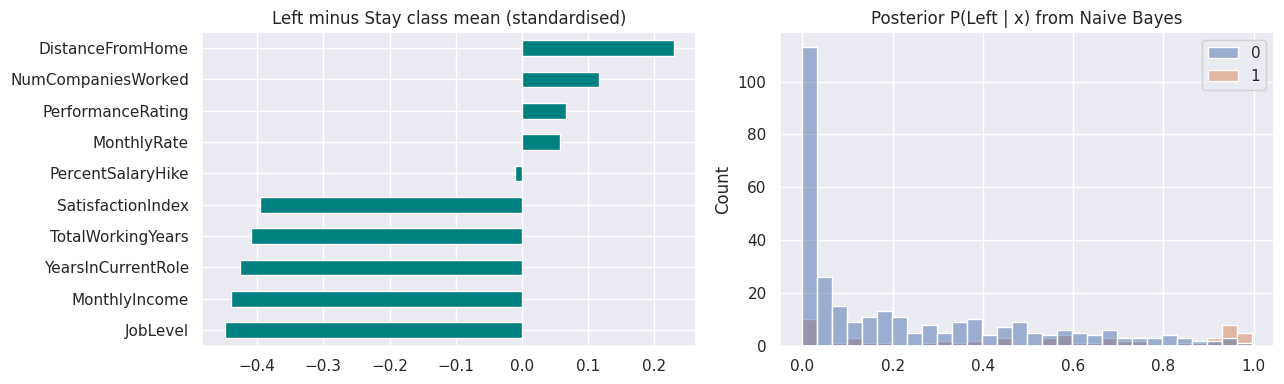


Employee example -> posterior P(Left) = 0.000 (actual: Stayed)


In [5]:
nb = models['Gaussian Naive Bayes']; g = nb.named_steps['clf']
print('Class priors  P(Stay)=%.3f  P(Left)=%.3f' % tuple(g.class_prior_))
shift = pd.Series(g.theta_[1] - g.theta_[0], index=num_cols).sort_values()
print('\nFeatures whose standardised mean differs most between Left and Stay:')
top = pd.concat([shift.head(5), shift.tail(5)]); print(top.round(3))
post = nb.predict_proba(X_test)[:,1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
top.plot(kind='barh', ax=ax[0], color='teal'); ax[0].set_title('Left minus Stay class mean (standardised)')
sns.histplot(x=post, hue=y_test.values, bins=30, ax=ax[1]); ax[1].set_title('Posterior P(Left | x) from Naive Bayes')
plt.tight_layout(); plt.savefig('outputs/bayes.png', dpi=130); plt.show()
# Worked posterior for one employee
i = 0; x_i = X_test.iloc[[i]]
print('\nEmployee example -> posterior P(Left) = %.3f (actual: %s)' % (nb.predict_proba(x_i)[0,1], 'Left' if y_test.iloc[i] else 'Stayed'))

## 5. Discriminant Analysis (LDA / QDA) - assumption checks
LDA assumes Gaussian classes with a **common covariance matrix**; QDA allows different covariances. We check skewness and covariance similarity, then compare the two.

Most skewed numeric features (|skew|>1 suggests non-normality):
StabilityScore             2.99
YearsSinceLastPromotion    2.04
PerformanceRating          1.98
YearsAtCompany             1.78
MonthlyIncome              1.39
TotalWorkingYears          1.16
dtype: float64

Relative Frobenius difference between class covariances: 0.18 (large => equal-covariance assumption is doubtful)


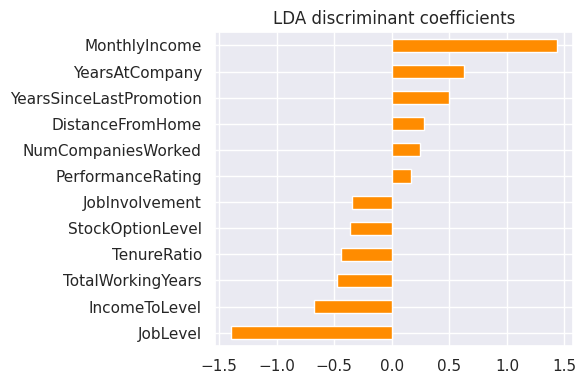

                      Recall     F1  ROC-AUC  CV AUC (train)
LDA                    0.186  0.301    0.785           0.728
QDA                    0.305  0.379    0.791           0.698
Gaussian Naive Bayes   0.576  0.463    0.750           0.715


In [6]:
num_df = X_train[num_cols]
skew = num_df.skew().abs().sort_values(ascending=False)
print('Most skewed numeric features (|skew|>1 suggests non-normality):'); print(skew.head(6).round(2))
cov_L = np.cov(num_df[y_train==1].T); cov_S = np.cov(num_df[y_train==0].T)
ratio = np.linalg.norm(cov_L - cov_S) / np.linalg.norm(cov_S)
print('\nRelative Frobenius difference between class covariances: %.2f (large => equal-covariance assumption is doubtful)' % ratio)
lda = models['LDA']; coef = pd.Series(lda.named_steps['clf'].coef_[0], index=num_cols).sort_values()
pd.concat([coef.head(6), coef.tail(6)]).plot(kind='barh', figsize=(6,4), color='darkorange'); plt.title('LDA discriminant coefficients'); plt.tight_layout()
plt.savefig('outputs/lda_coef.png', dpi=130); plt.show()
print(comparison.loc[['LDA','QDA','Gaussian Naive Bayes'], ['Recall','F1','ROC-AUC','CV AUC (train)']])

## 6. Pick the best model, tune it, and set the decision threshold
The best model is chosen on **cross-validated AUC of the training set** (not the test set) to avoid selection bias.

In [7]:
spaces = {
 'Logistic Regression': {'clf__C': loguniform(1e-3, 1e1)},
 'Random Forest': {'clf__n_estimators': randint(150, 500), 'clf__max_depth': randint(4, 16), 'clf__min_samples_leaf': randint(1, 10), 'clf__max_features': ['sqrt','log2', 0.4]},
 'XGBoost': {'clf__n_estimators': randint(100, 500), 'clf__max_depth': randint(2, 6), 'clf__learning_rate': loguniform(0.01, 0.2), 'clf__subsample': uniform(0.6, 0.4), 'clf__colsample_bytree': uniform(0.5, 0.5)},
 'Neural Network (MLP)': {'clf__hidden_layer_sizes': [(32,), (64,32), (32,16), (64,)], 'clf__alpha': loguniform(0.3, 10)},
}
best_name = comparison['CV AUC (train)'].idxmax(); best_model = models[best_name]; print('Best model by CV AUC:', best_name)
if best_name in spaces:
    rs = RandomizedSearchCV(models[best_name], spaces[best_name], n_iter=20, cv=skf, scoring='roc_auc', random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    if rs.best_score_ >= comparison.loc[best_name, 'CV AUC (train)']:
        best_model = rs.best_estimator_
    print('Tuned CV AUC: %.3f  params: %s' % (rs.best_score_, rs.best_params_))
oof = cross_val_predict(best_model, X_train, y_train, cv=skf, method='predict_proba')[:, 1]

Best model by CV AUC: Logistic Regression


Tuned CV AUC: 0.809  params: {'clf__C': np.float64(0.5210986937158466)}


In [8]:
prec, rec, thr = precision_recall_curve(y_train.values, oof)
f1s = 2*prec*rec/(prec+rec+1e-9)
best_thr = float(thr[np.argmax(f1s[:-1])])
print('Threshold (max F1 on out-of-fold scores): %.3f' % best_thr)
default_m = evaluate(best_model, X_test, y_test); tuned_m = evaluate(best_model, X_test, y_test, thr=best_thr)
final = pd.DataFrame({'Default (0.50)': default_m, 'Tuned (%.2f)' % best_thr: tuned_m}).T.round(3); final.to_csv('outputs/final_metrics.csv'); final

Threshold (max F1 on out-of-fold scores): 0.667


,Accuracy,Precision,Recall,F1,ROC-AUC
Default (0.50),0.766,0.387,0.780,0.517,0.855
Tuned (0.67),0.861,0.557,0.661,0.605,0.855


The decision threshold maximises F1 on out-of-fold predictions of the training data.

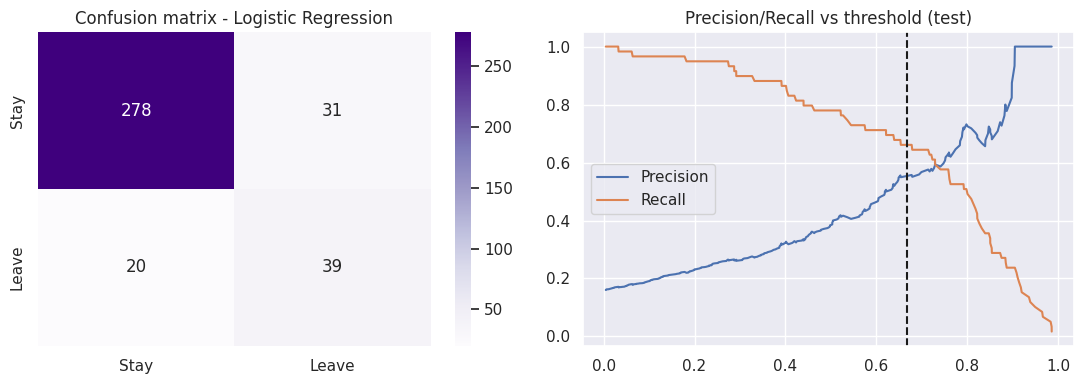

In [9]:
proba_te = best_model.predict_proba(X_test)[:,1]
cm = confusion_matrix(y_test, (proba_te >= best_thr).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=ax[0], xticklabels=['Stay','Leave'], yticklabels=['Stay','Leave']); ax[0].set_title(f'Confusion matrix - {best_name}')
prec_, rec_, thr_ = precision_recall_curve(y_test, proba_te); ax[1].plot(thr_, prec_[:-1], label='Precision'); ax[1].plot(thr_, rec_[:-1], label='Recall'); ax[1].axvline(best_thr, c='k', ls='--'); ax[1].legend(); ax[1].set_title('Precision/Recall vs threshold (test)')
plt.tight_layout(); plt.savefig('outputs/evaluation.png', dpi=130); plt.show()

## 7. Final model, risk categories and dashboard data
For the dashboard, every employee gets an **out-of-fold** risk score (each score comes from a model that never saw that employee), so the dashboard is not over-optimistic. Risk bands are defined relative to the tuned threshold: High >= threshold, Medium >= threshold/2, otherwise Low.

In [10]:
oof_all = cross_val_predict(best_model, X, y, cv=skf, method='predict_proba')[:, 1]
dash = df.copy(); dash['RiskScore'] = oof_all
dash['RiskCategory'] = pd.cut(oof_all, [-1, best_thr/2, best_thr, 2], labels=['Low','Medium','High'])
dash['AttritionFlag'] = (dash['Attrition']=='Yes').astype(int)
dash.to_csv('outputs/dashboard_data.csv', index=False)
print(dash['RiskCategory'].value_counts())
print(dash.groupby('RiskCategory')['AttritionFlag'].mean().round(3).rename('actual attrition rate in band'))

# Fit the final model on ALL data for deployment and save it
final_model = best_model.fit(X_train, y_train)          # evaluated model (train only) is what we report
deploy_model = __import__('sklearn.base', fromlist=['clone']).clone(best_model).fit(X, y)
joblib.dump(deploy_model, 'outputs/attrition_model.joblib')
defaults = {c: (float(X[c].median()) if c in num_cols else str(X[c].mode()[0])) for c in X.columns}
meta = {'best_model': best_name, 'threshold': best_thr, 'risk_bands': {'low_max': best_thr/2, 'medium_max': best_thr},
        'feature_columns': X.columns.tolist(), 'numeric': num_cols, 'categorical': cat_cols, 'defaults': defaults,
        'test_metrics_default': default_m, 'test_metrics_tuned': tuned_m, 'comparison': comparison.to_dict('index'),
        'attrition_rate': float(y.mean()), 'n_employees': int(len(df))}
json.dump(meta, open('outputs/model_meta.json','w'), indent=2, default=str); print('Saved model + metadata')

RiskCategory
Low       799
Medium    384
High      287
Name: count, dtype: int64
RiskCategory
Low       0.049
Medium    0.143
High      0.498
Name: actual attrition rate in band, dtype: float64


Saved model + metadata


## 8. HR KPIs (also shown in the dashboard)

In [11]:
headcount = len(dash); left = int(dash['AttritionFlag'].sum())
print('Headcount: %d | Left: %d | Attrition rate: %.1f%% | Retention rate: %.1f%%' % (headcount, left, 100*left/headcount, 100*(1-left/headcount)))
kpi_dept = dash.groupby('Department').agg(Headcount=('AttritionFlag','size'), Left=('AttritionFlag','sum'), AvgRisk=('RiskScore','mean'))
kpi_dept['AttritionRate%'] = (100*kpi_dept['Left']/kpi_dept['Headcount']).round(1); kpi_dept['AvgRisk'] = kpi_dept['AvgRisk'].round(3)
kpi_dept.to_csv('outputs/kpi_by_department.csv'); kpi_dept

Headcount: 1470 | Left: 237 | Attrition rate: 16.1% | Retention rate: 83.9%


,Headcount,Left,AvgRisk,AttritionRate%
Department,,,,
Human Resources,63,12,0.422,19.0
Research & Development,961,133,0.325,13.8
Sales,446,92,0.434,20.6


## 9. Deployment on IBM Watson Studio / Watson Machine Learning
Run this section inside a Watson Studio project notebook after setting your credentials as environment variables (or paste them). It is guarded so the notebook still runs end-to-end without credentials.

Steps: (1) create a Watson Studio project and associate a Watson Machine Learning service, (2) create a Deployment Space, (3) store the model, (4) create an online deployment, (5) score it.

In [12]:
WML_URL = os.getenv('WML_URL', 'https://us-south.ml.cloud.ibm.com')
WML_APIKEY = os.getenv('WML_APIKEY'); SPACE_ID = os.getenv('WML_SPACE_ID')
if WML_APIKEY and SPACE_ID:
    from ibm_watsonx_ai import APIClient
    client = APIClient({'url': WML_URL, 'apikey': WML_APIKEY}); client.set.default_space(SPACE_ID)
    sw = client.software_specifications.get_id_by_name('runtime-24.1-py3.11')
    mp = client.repository.ModelMetaNames
    stored = client.repository.store_model(deploy_model, meta_props={mp.NAME: 'attrition_model', mp.TYPE: 'scikit-learn_1.3', mp.SOFTWARE_SPEC_ID: sw},
                                           training_data=X, training_target=y)
    model_id = client.repository.get_model_id(stored)
    dp = client.deployments.ConfigurationMetaNames
    dep = client.deployments.create(model_id, meta_props={dp.NAME: 'attrition_scoring_endpoint', dp.ONLINE: {}})
    dep_id = client.deployments.get_id(dep); print('Deployment id:', dep_id, '| scoring URL:', client.deployments.get_scoring_href(dep))
    payload = {'input_data': [{'fields': X.columns.tolist(), 'values': X.iloc[:2].values.tolist()}]}
    print(client.deployments.score(dep_id, payload))
else:
    print('WML_APIKEY / WML_SPACE_ID not set - skipping live deployment. Set them in Watson Studio to deploy.')

WML_APIKEY / WML_SPACE_ID not set - skipping live deployment. Set them in Watson Studio to deploy.


### REST scoring endpoint (call from any language)
`score_client.py` (provided) gets an IAM token from your API key and calls `POST {WML_URL}/ml/v4/deployments/{deployment_id}/predictions?version=2021-05-01`. Request body: `{"input_data":[{"fields":[...],"values":[[...]]}]}`. Response: `{"predictions":[{"fields":["prediction","probability"],"values":[[1,[0.28,0.72]]]}]}`. The client applies the same `hr_features.prepare` step first, so raw HR records can be sent.

## 10. Automated retraining with Watson Studio Jobs
Upload `retrain_job.py` (provided) to the project, then **Jobs -> Create job -> choose the script -> Schedule** (for example weekly). The job retrains, compares the new CV AUC against the live model, and redeploys only when it is better.

In [13]:
print(open('retrain_job.py').read()[:1500] if os.path.exists('retrain_job.py') else 'retrain_job.py not found next to the notebook')

"""Watson Studio Job script: retrain the attrition model and redeploy only if it improves.
Schedule via Watson Studio: Jobs -> Create job -> select this script -> Schedule (e.g. weekly).
Environment variables: WML_URL, WML_APIKEY, WML_SPACE_ID, DEPLOYMENT_ID (optional), DATA_URL (optional)."""
import os, json, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from hr_features import prepare

DATA_URL = os.getenv("DATA_URL", "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv")
SEED = 7

def main():
    df = pd.read_csv(DATA_URL, encoding="utf-8-sig")
    data = prepare(df)
    y = (data["Attrition"] == "Yes").astype(int); X

## 11. Summary
The final summary table below goes into the report.

In [14]:
print('Best model:', best_name, '| threshold: %.3f' % best_thr)
display(comparison); display(final)

Best model: Logistic Regression | threshold: 0.667


,Accuracy,Precision,Recall,F1,ROC-AUC,CV AUC (train)
Logistic Regression,0.769,0.390,0.780,0.520,0.853,0.808
Random Forest,0.861,0.654,0.288,0.400,0.837,0.783
XGBoost,0.848,0.523,0.576,0.548,0.849,0.780
Neural Network (MLP),0.870,0.628,0.458,0.529,0.833,0.779
LDA,0.861,0.786,0.186,0.301,0.785,0.728
Gaussian Naive Bayes,0.785,0.386,0.576,0.463,0.750,0.715
QDA,0.840,0.500,0.305,0.379,0.791,0.698


,Accuracy,Precision,Recall,F1,ROC-AUC
Default (0.50),0.766,0.387,0.780,0.517,0.855
Tuned (0.67),0.861,0.557,0.661,0.605,0.855
